# Étape 2 — Moteur de prédiction : comparer, optimiser, choisir, évaluer (corrigé)

**Objectif.** À partir du jeu consolidé (notebook 1), construire le modèle qui prédit le rendement d'une culture,
l'optimiser de façon systématique, **tracer chaque expérience dans MLflow**, puis évaluer honnêtement :
(1) l'erreur sur des pays jamais vus, (2) la qualité du classement des cultures (recommandation).

Ce notebook exécute le **vrai pipeline** (`agrireco.train` puis `agrireco.evaluate`, les mêmes fonctions que la
commande `uv run agrireco all`) et en commente les résultats. Toutes les règles ont été fixées **avant** de voir les
résultats, dans `PLAN.md`.

| Étape du pipeline | Fonction | Sortie |
|---|---|---|
| préparer | `evaluate.run_prepare` | `data/processed/dataset_consolide.csv` |
| entraîner | `train.run_train` | runs MLflow + `data/processed/selection.json` |
| évaluer | `evaluate.run_evaluate` | `data/processed/resultats.json` + `models/model.joblib` |

## 1. Configuration et données

In [1]:
import json
import shutil
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.model_selection import GroupKFold, KFold, cross_val_score

from agrireco import config, io, metrics, modeling, prepare, recommend, service, split, viz
from agrireco.evaluate import run_evaluate, run_prepare
from agrireco.train import RMSE_LOG, run_train
from agrireco.viz import CROPS_FR, fr, pct

viz.apply_style()
pd.set_option("display.precision", 3)
cfg = config.load_config()
print((io.PROJECT_DIR / "config.yaml").read_text(encoding="utf-8"))

# Configuration unique du pipeline (prepare → train → evaluate).
# Changer une valeur ici, puis relancer `uv run agrireco all` : rien n'est codé en dur ailleurs.

paths:
  processed: data/processed             # CSV consolidé, journaux, résultats (versionnés)
  models: models                        # modèle servi par l'API (versionné)
  mlruns: mlruns                        # suivi MLflow local (non versionné)

seed: 42

split:
  test_size: 0.2          # part des PAYS mis de côté pour le test final
  cv_folds: 5             # validation croisée groupée par pays, sur les pays d'entraînement
  sensitivity_splits: 20  # découpages répétés pour mesurer la sensibilité au tirage des pays

features:
  - crop
  - avg_temp
  - rainfall_mm
  - log10_pesticides_t

# Variantes de variables comparées avec le modèle retenu (ce qu'ajoute chaque variable au-delà de la culture)
feature_variants:
  culture_seule: [crop]
  culture_pluie: [crop, rainfall_mm]
  culture_pluie_temperature: [crop, rainfall_m

Tout ce qui peut changer un résultat est dans **un seul fichier**, `config.yaml` : graine, part des pays mis de côté,
nombre de plis, variables, plages d'hyperparamètres. Rien n'est codé en dur dans les scripts.

In [2]:
df = prepare.add_model_features(run_prepare(cfg))
train, test = split.group_test_split(df, cfg["split"]["test_size"], cfg["seed"])
print(f"entraînement : {train['country'].nunique()} pays, {len(train)} lignes")
print(f"test         : {test['country'].nunique()} pays, {len(test)} lignes, {test['crop'].nunique()} cultures sur 10")
assert set(train["country"]).isdisjoint(test["country"]), "un pays est des deux côtés"
print("pays de test :", ", ".join(sorted(test["country"].unique())))

entraînement : 95 pays, 12339 lignes
test         : 24 pays, 3455 lignes, 10 cultures sur 10
pays de test : Albania, Armenia, Bangladesh, Belarus, Burundi, Croatia, Ecuador, Greece, Guinea, Haiti, Italy, Kazakhstan, Madagascar, Mauritius, Mozambique, Republic of Moldova, Romania, Russian Federation, Slovenia, South Africa, Spain, Ukraine, United Republic of Tanzania, Zambia


**Le découpage se fait par pays, pas par ligne.** 20 % des pays (24 sur 119) sont mis de côté et ne seront regardés
qu'**une fois**, à la toute fin. Les 10 cultures sont présentes dans le test.

Pourquoi par pays ? Parce qu'une même culture dans un même pays change très peu d'une année à l'autre. Si l'on tire
les lignes au hasard, le modèle voit le maïs français de 2004 à l'entraînement et doit « prédire » celui de 2005 au
test : il lui suffit de s'en souvenir. On ne mesurerait pas sa capacité à servir un **nouveau** client.

## 2. Pourquoi la validation croisée doit être groupée par pays

In [3]:
rf_default = modeling.build_model("random_forest", cfg["models"]["random_forest"], cfg["features"], cfg["seed"])
random_cv = -cross_val_score(rf_default, train, train["yield_t_ha"], scoring=RMSE_LOG,
                             cv=KFold(5, shuffle=True, random_state=cfg["seed"]), n_jobs=-1)
group_cv = -cross_val_score(rf_default, train, train["yield_t_ha"], scoring=RMSE_LOG, groups=train["country"],
                            cv=GroupKFold(5, shuffle=True, random_state=cfg["seed"]), n_jobs=-1)
print(f"forêt aléatoire, réglages par défaut — RMSE du log du rendement")
print(f"  validation aléatoire (lignes mélangées) : {fr(random_cv.mean(), 3)}")
print(f"  validation groupée par pays             : {fr(group_cv.mean(), 3)}")

forêt aléatoire, réglages par défaut — RMSE du log du rendement
  validation aléatoire (lignes mélangées) : 0,277
  validation groupée par pays             : 0,785


**La même forêt aléatoire** paraît excellente quand on mélange les lignes (RMSE-log ≈ 0,28, soit environ 30 %
d'erreur) et devient mauvaise sur des pays qu'elle n'a pas vus (≈ 0,79). Elle a **mémorisé les pays** : avec la pluie
(une valeur fixe par pays) et les pesticides, elle reconnaît chaque pays et ressort ses rendements. C'est pourquoi
**toutes** les comparaisons du projet utilisent une validation croisée groupée par pays, sur les **mêmes plis**
pour tous les modèles (comparaisons appariées).

> **RMSE du log du rendement**, la métrique principale : une erreur de 0,1 correspond à environ 10 % d'erreur
> relative, quelle que soit la culture. Elle traite à égalité le soja (1,6 t/ha) et la pomme de terre (16 t/ha).

## 3. Entraînement : comparaison, optimisation, sélection (MLflow)

`run_train` enchaîne trois expériences MLflow :

1. **p12-01-comparaison** : référence naïve (médiane de la culture, sans regarder les conditions), Ridge, forêt
   aléatoire et gradient boosting avec leurs réglages de départ ;
2. **p12-02-optimisation** : grille complète pour Ridge (5 valeurs d'`alpha`), 30 tirages aléatoires
   (`RandomizedSearchCV`) pour chaque modèle d'arbres ; chaque essai est un run MLflow enfant ;
3. **p12-03-variantes-variables** : le modèle retenu avec moins de variables, pour mesurer ce que chacune apporte.

Chaque run enregistre ses paramètres, la graine, la RMSE-log par pli, sa moyenne et son écart-type, l'erreur
d'entraînement et l'écart entre les deux (signal de surapprentissage). On repart d'un suivi vide pour que les
captures correspondent exactement à ce notebook.

In [4]:
shutil.rmtree(cfg["paths"]["mlruns"], ignore_errors=True)
selection = run_train(cfg)
print("modèle retenu :", selection["selected"], selection["params"])

2026/10/25 03:36:35 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/25 03:36:35 INFO mlflow.store.db.utils: Updating database tables


modèle retenu : ridge {'alpha': 10.0}


In [5]:
rows = []
for name, folds in selection["comparison_folds"].items():
    rows.append({"modèle": name, "réglage": "départ", "CV RMSE-log": np.mean(folds), "écart-type": np.std(folds, ddof=1)})
for name, res in selection["search"].items():
    rows.append({"modèle": name, "réglage": "optimisé", "CV RMSE-log": np.mean(res["folds"]),
                 "écart-type": np.std(res["folds"], ddof=1), "RMSE-log entraînement": np.mean(res["train_folds"])})
table = pd.DataFrame(rows)
table["écart val − entr."] = table["CV RMSE-log"] - table["RMSE-log entraînement"]
table.round(3)

,modèle,réglage,CV RMSE-log,écart-type,RMSE-log entraînement,écart val − entr.
0,baseline,départ,0.734,0.043,NaN,NaN
1,ridge,départ,0.641,0.068,NaN,NaN
2,random_forest,départ,0.785,0.109,NaN,NaN
3,hist_gb,départ,0.680,0.081,NaN,NaN
4,ridge,optimisé,0.641,0.069,0.622,0.019
5,random_forest,optimisé,0.634,0.071,0.471,0.164
6,hist_gb,optimisé,0.638,0.075,0.445,0.194


In [6]:
pd.DataFrame({k: v["params"] for k, v in selection["search"].items()}).T

,alpha,n_estimators,min_samples_leaf,max_features,max_depth,max_leaf_nodes,max_iter,learning_rate,l2_regularization
ridge,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
random_forest,NaN,300.0,50.0,0.5,20.0,NaN,NaN,NaN,NaN
hist_gb,NaN,NaN,50.0,NaN,NaN,15.0,100.0,0.05,1.0


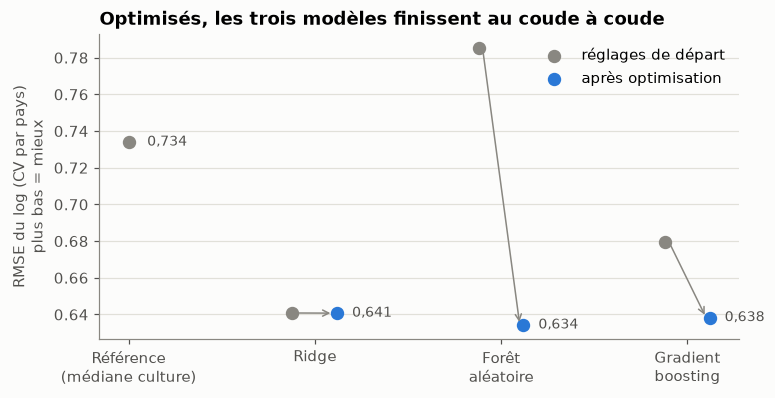

In [7]:
order = ["baseline", "ridge", "random_forest", "hist_gb"]
labels = {"baseline": "Référence\n(médiane culture)", "ridge": "Ridge", "random_forest": "Forêt\naléatoire",
          "hist_gb": "Gradient\nboosting"}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, name in enumerate(order):
    start = np.mean(selection["comparison_folds"][name])
    best = np.mean(selection["candidate_folds"][name])
    if name == "baseline":  # rien à optimiser : un seul point
        ax.scatter(i, start, s=60, color=viz.MUTED, zorder=3)
        ax.text(i + 0.1, start, fr(start, 3), va="center", color=viz.TEXT_2, fontsize=9)
        continue
    ax.scatter(i - 0.12, start, s=60, color=viz.MUTED, zorder=3, label="réglages de départ" if i == 1 else None)
    ax.scatter(i + 0.12, best, s=60, color=viz.BLUE, zorder=3, label="après optimisation" if i == 1 else None)
    ax.text(i + 0.2, best, fr(best, 3), va="center", color=viz.TEXT_2, fontsize=9)
    ax.annotate("", xy=(i + 0.1, best), xytext=(i - 0.1, start),
                arrowprops={"arrowstyle": "->", "color": viz.MUTED, "lw": 1})
ax.set_xticks(range(4), [labels[n] for n in order])
ax.set_ylabel("RMSE du log (CV par pays)\nplus bas = mieux")
ax.set_title("Optimisés, les trois modèles finissent au coude à coude")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
viz.save(fig, "cv_modeles")
plt.show()

**Ce que montrent les expériences**

- **La référence naïve** (la médiane de la culture, sans aucune condition) fait 0,734 : c'est la barre à franchir.
- **La forêt aléatoire par défaut (0,785) fait pire que la référence** : elle apprend chaque pays par cœur. Le
  réglage décisif est `min_samples_leaf = 50` (chaque feuille doit contenir au moins 50 lignes, soit plusieurs pays) :
  la forêt optimisée descend à 0,634. Même chose pour le gradient boosting (0,680 → 0,638).
- **Ridge** (régression linéaire régularisée) fait 0,641 et presque rien ne change avec `alpha` : un modèle peu
  flexible a peu de choses à régler, et il ne peut pas mémoriser les pays (écart validation − entraînement 0,019,
  contre 0,16 à 0,19 pour les arbres optimisés).
- Les trois modèles optimisés sont **à moins de 0,01 l'un de l'autre**, pour un écart-type entre plis d'environ 0,07.

**Règle de sélection (fixée dans le PLAN).** On compare chaque modèle au meilleur **pli par pli** ; si l'écart moyen
est inférieur à son erreur-type, on garde le plus simple (référence < Ridge < forêt < boosting).

In [8]:
cand = {k: np.array(v) for k, v in selection["candidate_folds"].items()}
best = min(cand, key=lambda k: cand[k].mean())
for name in ["ridge", "hist_gb"]:
    d = cand[name] - cand[best]
    print(f"{name:<8} − {best} : écart moyen {fr(d.mean(), 4)}, erreur-type {fr(d.std(ddof=1) / np.sqrt(len(d)), 4)}")
print("→ retenu :", modeling.select_model(selection["candidate_folds"]))

ridge    − random_forest : écart moyen 0,0065, erreur-type 0,0068
hist_gb  − random_forest : écart moyen 0,0040, erreur-type 0,0087
→ retenu : ridge


La forêt est la meilleure en moyenne, mais Ridge n'en est qu'à 0,0065, **moins qu'une erreur-type (0,0068)** :
la règle retient **Ridge**, le modèle le plus simple. Le choix tient à un cheveu : la forêt est légèrement meilleure
en validation croisée (0,634 contre 0,641), à moins d'une erreur-type. On ne dira donc pas que Ridge est « aussi bon » ou « le meilleur » :
il est **retenu par une règle de parcimonie fixée à l'avance**.

In [9]:
var = pd.DataFrame({k: {"CV RMSE-log": np.mean(v), "écart-type": np.std(v, ddof=1)}
                    for k, v in selection["variant_folds"].items()}).T
var["variables"] = [", ".join(cfg["feature_variants"][k]) for k in var.index]
var.sort_values("CV RMSE-log", ascending=False).round(3)

,CV RMSE-log,écart-type,variables
culture_pluie,0.735,0.040,"crop, rainfall_mm"
culture_seule,0.730,0.044,crop
culture_pluie_temperature,0.685,0.048,"crop, rainfall_mm, avg_temp"
culture_pesticides,0.649,0.070,"crop, log10_pesticides_t"
toutes,0.641,0.069,"crop, avg_temp, rainfall_mm, log10_pesticides_t"


**Ce qu'apporte chaque variable (Ridge, CV par pays).** La culture seule fait 0,730, autant que la référence.
Ajouter la pluie n'apporte rien (0,735). La température aide (0,685). Les **pesticides** apportent le plus
(culture + pesticides : 0,649 ; tout : 0,641). Rappel : les pesticides sont des tonnes nationales, ils mesurent la
taille et l'intensité de l'agriculture du pays ; ce n'est pas l'effet du produit sur une plante.

*(Écart au PLAN : la variante « tout sauf pesticides » prévue était identique, par erreur, à « culture + pluie +
température » ; elle a été remplacée par « culture + pesticides » après le premier lancement. Les variantes ne
servent à aucune sélection.)*

## 4. Évaluation finale sur les 24 pays mis de côté

In [10]:
res = run_evaluate(cfg)
t = res["test"]
print(f"RMSE-log test : {fr(t['rmse_log'], 3)}  (IC 95 % bootstrap par pays : {fr(t['rmse_log_ic95'][0], 2)} – {fr(t['rmse_log_ic95'][1], 2)})")
print(f"référence (médiane de la culture) : {fr(t['reference_mediane']['rmse_log'], 3)} | même modèle avec la culture seule : {fr(t['rmse_log_culture_seule'], 3)}")
print(f"erreur relative médiane : {pct(t['median_rel_error'], 0)} | MAE : {fr(t['mae_t_ha'])} t/ha | R² (log) : {fr(t['r2_log'])}")
print(f"RMSE-log entraînement : {fr(t['train_rmse_log'], 3)} | chaque pays pesant 1 : {fr(t['rmse_log_par_pays'], 3)}")
print(f"biais moyen (prédit − observé) : {fr(t['bias_t_ha'])} t/ha")
print(f"facteur typique entre prédiction et réalité : {fr(t['facteur_typique'])} ; "
      f"part des cas à moins d'un facteur {fr(t['facteur_exp_rmse'], 1)} : {pct(t['part_dans_facteur_exp_rmse'], 0)}")

2026/10/25 03:37:50 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


RMSE-log test : 0,608  (IC 95 % bootstrap par pays : 0,53 – 0,68)
référence (médiane de la culture) : 0,699 | même modèle avec la culture seule : 0,680
erreur relative médiane : 37 % | MAE : 2,45 t/ha | R² (log) : 0,62
RMSE-log entraînement : 0,624 | chaque pays pesant 1 : 0,577
biais moyen (prédit − observé) : 0,54 t/ha
facteur typique entre prédiction et réalité : 1,47 ; part des cas à moins d'un facteur 1,8 : 70 %


**Lecture pour un débutant.** Sur 24 pays jamais vus, le modèle se trompe typiquement de **37 %** (erreur relative
médiane) sur le rendement moyen national d'une culture ; en RMSE-log, 0,61 (intervalle 0,53 – 0,68), contre 0,70 pour
la simple médiane de la culture. Dans un cas typique, prédiction et réalité diffèrent d'un facteur 1,47 ; dans
environ 7 cas sur 10, d'un facteur inférieur à 1,8 : un rendement réel de 4 t/ha est alors prédit entre 2,2 et
7,3 t/ha ; dans les autres cas, l'écart est plus grand. Les conditions du pays améliorent l'erreur de 0,68 (culture
seule) à 0,61 : c'est réel mais modeste.

L'erreur d'entraînement (0,624) est proche de celle du test (0,608) : pas de signe de surapprentissage, ce qui est
attendu pour un modèle linéaire. Le test se situe au milieu des 20 autres tirages de pays (médiane 0,60, voir plus
bas).

In [11]:
per_crop = pd.read_csv(io.PROJECT_DIR / "data/processed/test_par_culture.csv")
per_crop.assign(culture=per_crop["crop"].map(CROPS_FR)).set_index("culture")[["n", "rmse_log", "r2_log", "median_rel_error", "bias_t_ha"]].round(2)

,n,rmse_log,r2_log,median_rel_error,bias_t_ha
culture,,,,,
Manioc,207,0.54,-0.78,0.35,1.23
Maïs,536,0.67,0.34,0.50,-0.82
Banane plantain,92,0.55,-0.28,0.39,1.97
Pomme de terre,523,0.58,-0.13,0.38,3.10
Riz,398,0.60,0.15,0.30,0.50
Sorgho,430,0.66,0.21,0.46,-0.24
Soja,388,0.49,0.18,0.30,-0.00
Patate douce,322,0.72,0.13,0.35,0.36
Blé,467,0.61,-0.10,0.34,0.19


⚠️ **Le R² global (0,62) est trompeur.** À l'intérieur d'une culture, le R² est **négatif pour 5 cultures sur 10**
(manioc, plantain, pomme de terre, blé, igname) : pour ces cultures, le modèle prédit moins bien les écarts entre
pays que la simple moyenne de la culture dans ces pays. Le « 62 % de variance expliquée » vient surtout des écarts
**entre** cultures (une pomme de terre pèse plus qu'un soja), pas de la qualité de prédiction pour une culture donnée.

In [12]:
sens = pd.read_csv(io.PROJECT_DIR / "data/processed/sensibilite_decoupage.csv")
s = res["sensibilite"]
print(f"RMSE-log sur {s['n_decoupages']} autres tirages de pays : de {fr(s['rmse_log']['min'])} à {fr(s['rmse_log']['max'])} (médiane {fr(s['rmse_log']['mediane'])})")
b = s["biais_t_ha"]
print(f"biais : de {fr(b['min'])} à {fr(b['max'])} t/ha, négatif dans {b['negatif']} tirages sur {s['n_decoupages']}")

RMSE-log sur 20 autres tirages de pays : de 0,51 à 0,67 (médiane 0,60)
biais : de -1,95 à 0,26 t/ha, négatif dans 17 tirages sur 20


**Le signe du biais dépend des pays tirés.** Sur nos 24 pays de test, le modèle surestime en moyenne de 0,54 t/ha ;
sur 20 autres tirages de pays, il **sous-estime** le plus souvent (17 fois sur 20, médiane −0,87 t/ha). Une
sous-estimation en moyenne est attendue : le modèle apprend le log du rendement, et exp(prédiction) estime le
rendement **médian**, pas la moyenne. On ne peut donc ni écrire « le modèle surestime les rendements », ni corriger
les prédictions avec ce chiffre (une correction unique ne changerait d'ailleurs pas le classement).

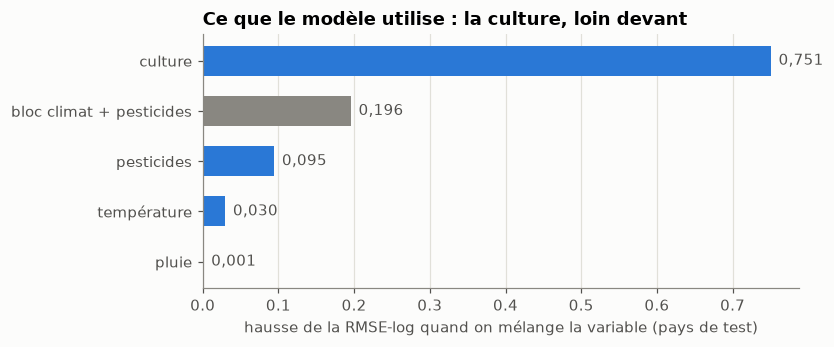

In [13]:
imp = pd.Series(res["importance"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(imp.index, imp.values, color=[viz.MUTED if "bloc" in i else viz.BLUE for i in imp.index], height=0.6)
for i, v in enumerate(imp.values):
    ax.text(v + 0.01, i, fr(v, 3), va="center", color=viz.TEXT_2)
ax.set_xlabel("hausse de la RMSE-log quand on mélange la variable (pays de test)")
ax.set_title("Ce que le modèle utilise : la culture, loin devant")
ax.grid(axis="y", visible=False)
viz.save(fig, "importance_permutation")
plt.show()

**Importance par permutation** : on mélange une variable entre les lignes du test et on regarde de combien l'erreur
augmente (10 répétitions). Lecture imposée par le PLAN : c'est la dégradation **de ce modèle, sur ces pays**, quand
on casse le lien d'une variable ; avec des variables corrélées, l'importance se partage de façon arbitraire ; elle
ne dit ni le sens ni la taille d'un effet.

- **Culture (0,75)** : attendu, une pomme de terre rapporte toujours plus de tonnes qu'un soja. Ce chiffre ne dit
  rien de la qualité de la recommandation, qui compare des rendements *relatifs*.
- **Pesticides (0,09)** : traduit d'abord la taille et l'intensité agricole du pays, **jamais** un effet des
  pesticides sur la plante.
- **Pluie (≈ 0)** : inutile à ce modèle, même seule (culture + pluie ne fait pas mieux que la culture seule).
  C'est une valeur fixe par pays, qui ne dit rien de l'année ; cela ne veut pas dire que la pluie ne compte pas pour
  une plante.
- Le **bloc** climat + pesticides mélangé d'un seul tenant (0,20) pèse plus que la somme des trois (0,13) : c'est
  l'effet des corrélations entre ces variables.

## 5. Recommandation : le classement des cultures est-il utile ?

L'application classe les cultures par **rendement relatif** : rendement prédit ÷ rendement habituel de la culture
(médiane des médianes par pays). « 1,3 » se lit « 30 % au-dessus de ce qu'on obtient d'habitude pour cette culture ».

**Comment l'évaluer ?** On ne sait pas ce qu'aurait donné une culture jamais plantée. La seule vérité disponible :
dans chaque pays de test et chaque année, parmi les cultures **réellement cultivées** (au moins 3), laquelle a eu le
meilleur rendement relatif ? On regarde si la culture classée 1ʳᵉ par le modèle est celle-là, et on compare à trois
références fixées dans le PLAN :

- **hasard** : choisir une des cultures au hasard ;
- **classement constant** : toujours le même ordre des cultures (celui qui marche le mieux en moyenne à
  l'entraînement), quelles que soient les conditions ;
- **oracle** : le meilleur résultat possible.

Règle de décision : le modèle n'est dit « utile pour recommander » que s'il **bat le classement constant** avec un
intervalle de confiance entièrement au-dessus de zéro.

In [14]:
r = res["recommandation"]
print(f"{r['n_pays_evalues']} pays, {r['n_pays_annees']} pays-années évalués ({fr(r['cultures_par_groupe_moyenne'], 1)} cultures en moyenne)")
print(f"bonne 1re place — modèle {pct(r['taux_top1_modele'])} | constant {pct(r['taux_top1_constant'])} | hasard {pct(r['taux_top1_hasard'])}")
lo, hi = r["diff_modele_moins_constant_ic95"]
print(f"modèle − constant : {fr(100 * r['diff_modele_moins_constant'], 1)} points (IC 95 % : {fr(100 * lo, 1)} à {fr(100 * hi, 1)})")
print("modèle utile pour recommander ?", r["modele_utile_pour_recommander"])
print(f"gain de rendement relatif — modèle {fr(r['gain_modele'])} | constant {fr(r['gain_constant'])} | oracle {fr(r['gain_oracle'])}")
print(f"tau de Kendall moyen — modèle {fr(r['kendall_modele'])} | constant {fr(r['kendall_constant'])}")

24 pays, 536 pays-années évalués (6,4 cultures en moyenne)
bonne 1re place — modèle 37,5 % | constant 39,6 % | hasard 17,2 %
modèle − constant : -2,1 points (IC 95 % : -10,2 à 7,5)
modèle utile pour recommander ? False
gain de rendement relatif — modèle 0,34 | constant 0,39 | oracle 0,79
tau de Kendall moyen — modèle 0,26 | constant 0,33


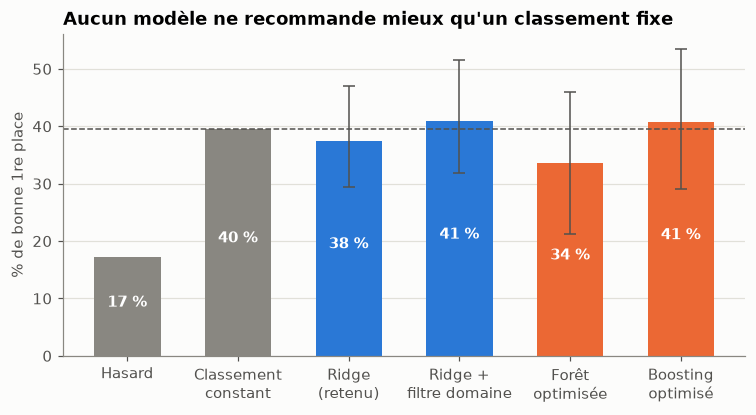

In [15]:
ac = res["analyse_complementaire"]
bars = [
    ("Hasard", r["taux_top1_hasard"], None, viz.MUTED),
    ("Classement\nconstant", r["taux_top1_constant"], None, viz.MUTED),
    ("Ridge\n(retenu)", r["taux_top1_modele"], r["diff_modele_moins_constant_ic95"], viz.BLUE),
    ("Ridge +\nfiltre domaine", r["filtre_taux_top1"], r["filtre_diff_moins_constant_ic95"], viz.BLUE),
    ("Forêt\noptimisée", ac["random_forest_optimise"]["taux_top1"], ac["random_forest_optimise"]["diff_moins_constant_ic95"], viz.ORANGE),
    ("Boosting\noptimisé", ac["hist_gb_optimise"]["taux_top1"], ac["hist_gb_optimise"]["diff_moins_constant_ic95"], viz.ORANGE),
]
fig, ax = plt.subplots(figsize=(8, 3.8))
const = r["taux_top1_constant"]
for i, (lab, v, ci, col) in enumerate(bars):
    ax.bar(i, 100 * v, color=col, width=0.6)
    if ci is not None:  # IC de la différence avec le classement constant, reporté autour de la barre
        ax.errorbar(i, 100 * v, yerr=[[100 * (v - (const + ci[0]))], [100 * ((const + ci[1]) - v)]],
                    color=viz.TEXT_2, capsize=4, lw=1)
    ax.text(i, 100 * v / 2, pct(v, 0), ha="center", color="white", fontweight="bold")
ax.axhline(100 * const, color=viz.TEXT_2, lw=1, ls="--")
ax.set_xticks(range(len(bars)), [b[0] for b in bars])
ax.set_ylabel("% de bonne 1re place")
ax.set_title("Aucun modèle ne recommande mieux qu'un classement fixe")
ax.grid(axis="x", visible=False)
viz.save(fig, "recommandation_top1")
plt.show()

*Barres d'erreur : intervalle à 95 % de la différence avec le classement constant (bootstrap par pays), reporté
autour du taux. Orange : modèles non retenus, évalués après coup (analyse complémentaire, déclarée dans le README).*

**Conclusion, fixée par la règle du PLAN : le modèle ne recommande pas mieux qu'un classement fixe des cultures.**

- Ridge trouve la meilleure culture dans 37,5 % des cas, bien plus que le hasard (17 %), mais un classement fixe fait
  39,6 %. L'écart (−2 points) a un intervalle de −10 à +7 points : indiscernable de zéro.
- Ce n'est pas un défaut de Ridge seulement : la forêt optimisée (−6 points) et le gradient boosting (+1 point) ne
  font pas mieux, intervalles contenant zéro.
- **Ridge classe toujours les cultures dans le même ordre.** Il additionne (en log) un effet « culture » et un effet
  « conditions » : changer les conditions monte ou descend toutes les cultures ensemble. La répartition des
  recommandations sur le test varie seulement parce que les cultures pratiquées varient d'un pays à l'autre.
- Dans 17 pays sur 24, Ridge et le classement fixe recommandent la même culture chaque année : la différence se
  joue sur 7 pays, ce qui rend l'intervalle de confiance fragile (peu de pays informatifs). Avec un autre normaliseur (médiane des lignes), l'écart change de signe (+3 points) mais reste
  indiscernable de zéro. Sur 20 autres tirages de pays : 9 fois mieux, 1 égalité, 10 fois moins bien.

In [16]:
print("répartition des recommandations (Ridge) :", {CROPS_FR[k]: v for k, v in r["repartition_recommandations"].items()})
print("répartition (classement constant)       :", {CROPS_FR[k]: v for k, v in r["repartition_constant"].items()})
print(f"pays où les deux diffèrent au moins une année : {r['pays_ou_modele_et_constant_different']} sur {r['n_pays_evalues']}")
lo, hi = r["diff_normaliseur_lignes_ic95"]
print(f"normaliseur « médiane des lignes » : modèle {pct(r['taux_top1_modele_normaliseur_lignes'])}, constant {pct(r['taux_top1_constant_normaliseur_lignes'])} (IC de l'écart {fr(100 * lo, 0)} à {fr(100 * hi, 0)} points)")
print(f"sensibilité (20 tirages) : modèle meilleur {s['modele_bat_constant']}, égalité {s['egalites']}, moins bon {s['modele_battu']}")

répartition des recommandations (Ridge) : {'Sorgho': 315, 'Maïs': 96, 'Igname': 92, 'Banane plantain': 23, 'Riz': 10}
répartition (classement constant)       : {'Sorgho': 430, 'Maïs': 106}
pays où les deux diffèrent au moins une année : 7 sur 24
normaliseur « médiane des lignes » : modèle 45,7 %, constant 42,5 % (IC de l'écart -15 à 23 points)
sensibilité (20 tirages) : modèle meilleur 9, égalité 1, moins bon 10


**Biais de sélection (formulation imposée).** Le taux et le gain ne valent que parmi les cultures déjà pratiquées
dans le pays ; la recommandation d'une culture jamais cultivée dans des conditions semblables n'est pas évaluée.

C'est pourquoi l'API signale les cultures **« non appuyées »** (aucun pays aux conditions proches ne les cultive) et
les relègue en fin de classement. Cette règle produit a été ajoutée après les résultats (écart déclaré) ; évaluée à
titre exploratoire, elle ne change pas la conclusion (40,9 % de bonne 1ʳᵉ place, intervalle de la différence avec le
classement fixe contenant zéro).

## 6. Modèle sauvegardé et rechargé

In [17]:
bundle = service.load_bundle(cfg["paths"]["models"] / "model.joblib")
print(bundle.metadata)
ctx = {"avg_temp": 10.0, "rainfall_mm": 700.0, "pesticides_t": 30000.0}
print(service.predict(bundle, "Wheat", **ctx))
ranking = pd.DataFrame(service.recommend_crops(bundle, **ctx)["ranking"])
ranking.assign(culture=ranking["crop"].map(CROPS_FR))[["rank", "culture", "relative_yield", "yield_t_ha", "crop_supported"]].round(2)

{'modele': 'ridge', 'params': {'alpha': 10.0}, 'features': ['crop', 'avg_temp', 'rainfall_mm', 'log10_pesticides_t'], 'n_lignes': 15794, 'periode': [1990, 2013], 'sklearn_version': '1.9.1'}
{'crop': 'Wheat', 'yield_t_ha': 3.530566215651566, 'relative_yield': 1.419437227375695, 'out_of_range': [], 'crop_supported': True}


,rank,culture,relative_yield,yield_t_ha,crop_supported
0,1,Sorgho,1.73,2.13,True
1,2,Riz,1.59,5.23,True
2,3,Patate douce,1.48,13.28,True
3,4,Maïs,1.46,4.23,True
4,5,Pomme de terre,1.44,23.02,True
5,6,Blé,1.42,3.53,True
6,7,Soja,1.27,2.04,True
7,8,Igname,1.99,17.43,False
8,9,Banane plantain,1.96,15.28,False
9,10,Manioc,1.61,16.39,False


Le modèle servi est la configuration retenue (Ridge, `alpha = 10`), **réentraînée sur les 119 pays** après
l'évaluation : le test a servi à estimer l'erreur, l'API profite de toutes les données. Le fichier
`models/model.joblib` (quelques kilo-octets) contient le modèle, les rendements de référence par culture et le
domaine de validité ; il ne se recharge qu'avec la même version de scikit-learn (contrôlé au chargement). C'est ce
fichier que l'API embarque dans son image Docker (étape 3).

## 7. Captures MLflow (livrable 1)

Pour explorer les runs : `uv run mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db`, puis
http://127.0.0.1:5000. Le script ci-dessous démarre un serveur MLflow, en fait des captures avec Chrome sans
interface et exporte tous les runs dans `data/processed/mlflow_runs.csv` (les chiffres visibles sur les captures).

In [18]:
out = subprocess.run([sys.executable, "scripts/captures_mlflow.py"], cwd=io.PROJECT_DIR, capture_output=True, text=True)
print(out.stdout[-600:] or out.stderr[-600:])

export : data/processed/mlflow_runs.csv (78 runs)
capture : presentation/figures/mlflow_1_comparaison.png
capture : presentation/figures/mlflow_2_optimisation.png
capture : presentation/figures/mlflow_3_comparaison_modeles.png
capture : presentation/figures/mlflow_4_variantes.png
capture : presentation/figures/mlflow_5_run_final.png



mlflow_1_comparaison


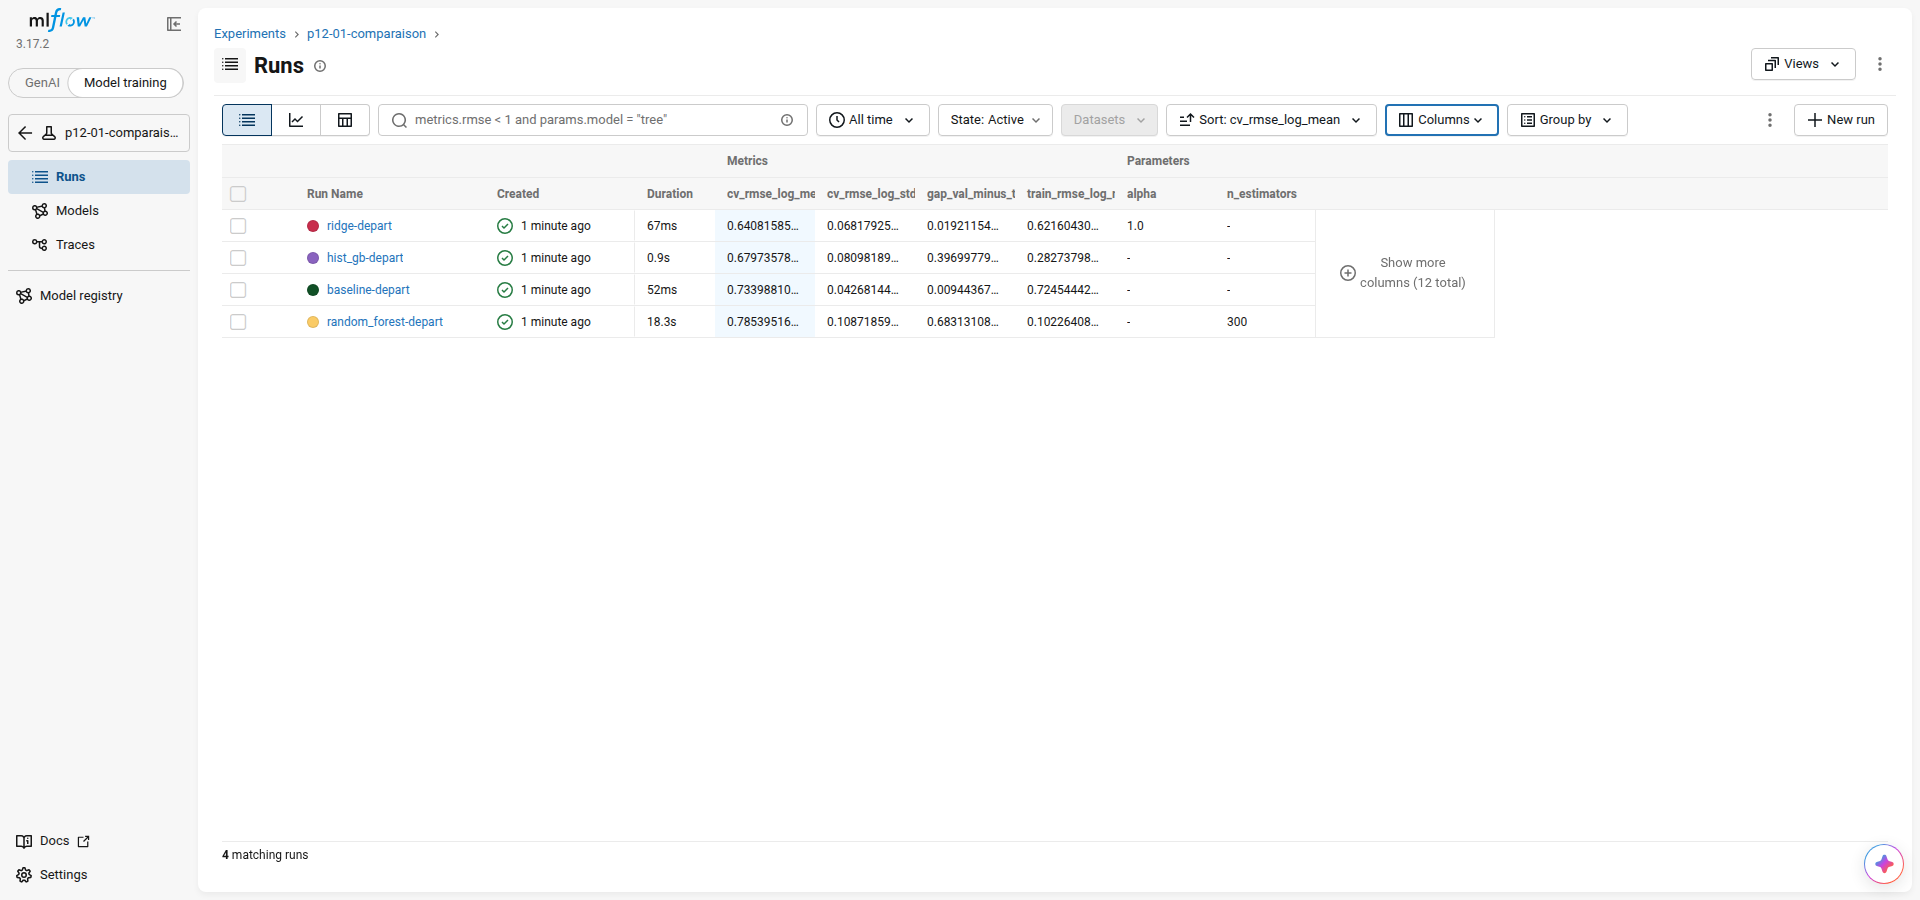

mlflow_2_optimisation


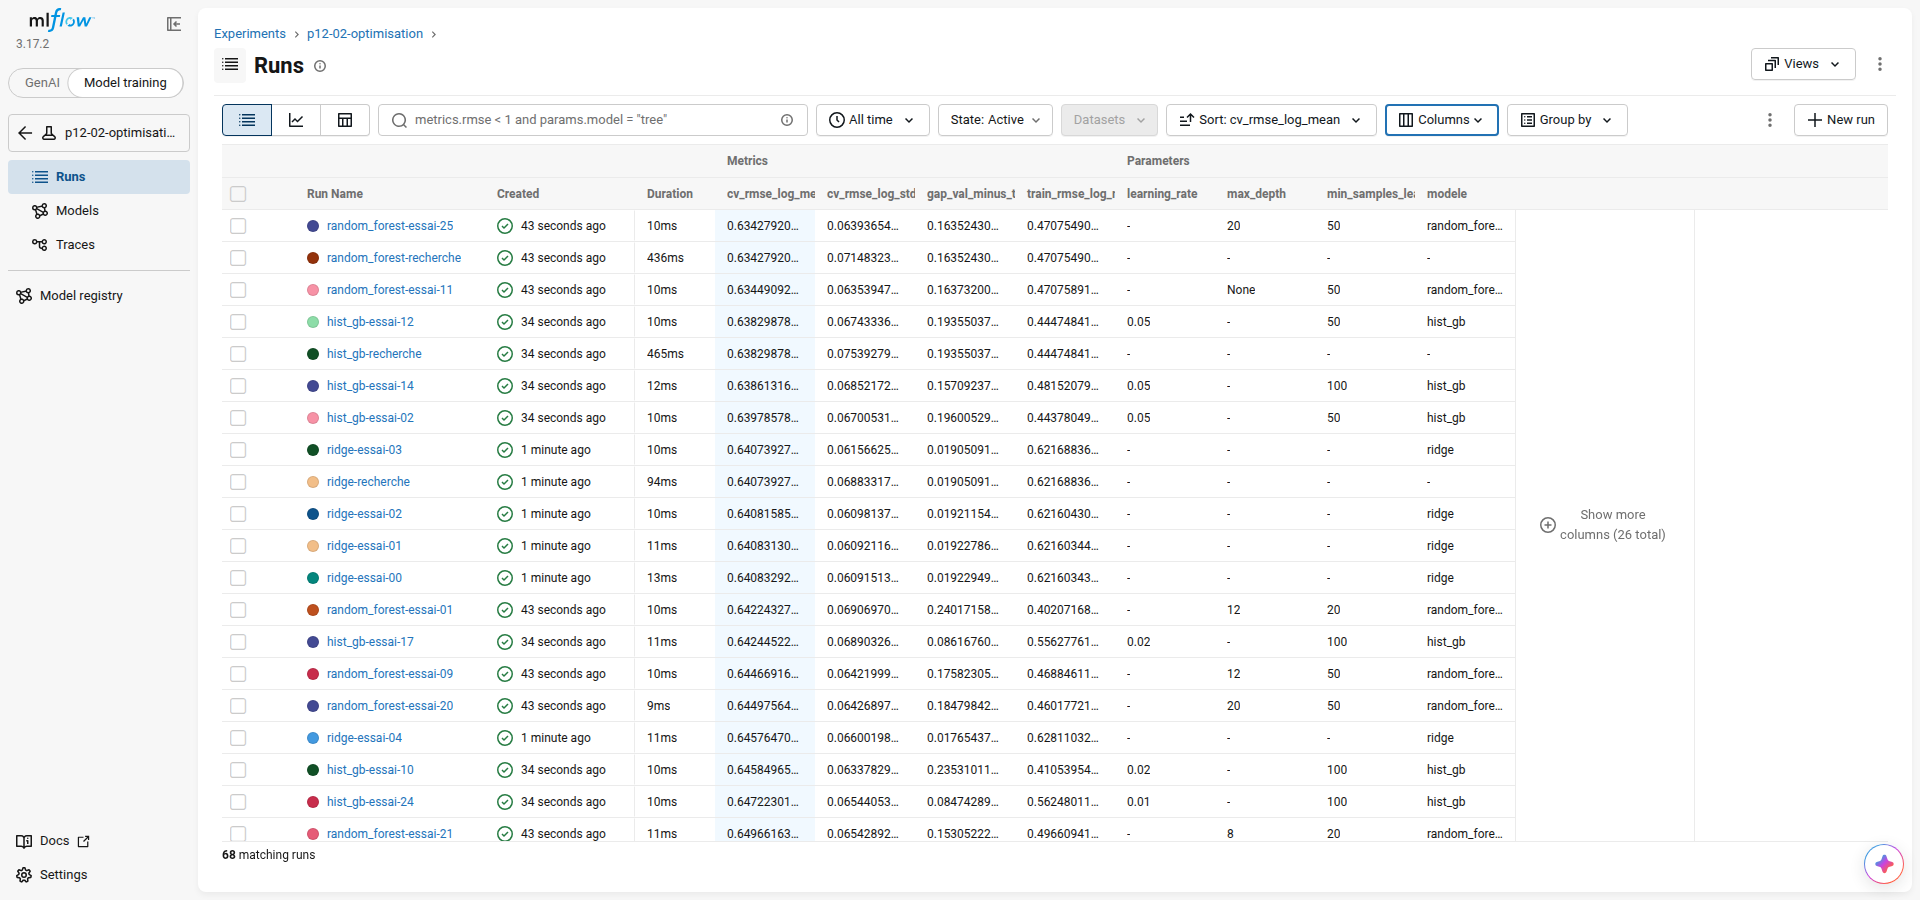

mlflow_3_comparaison_modeles


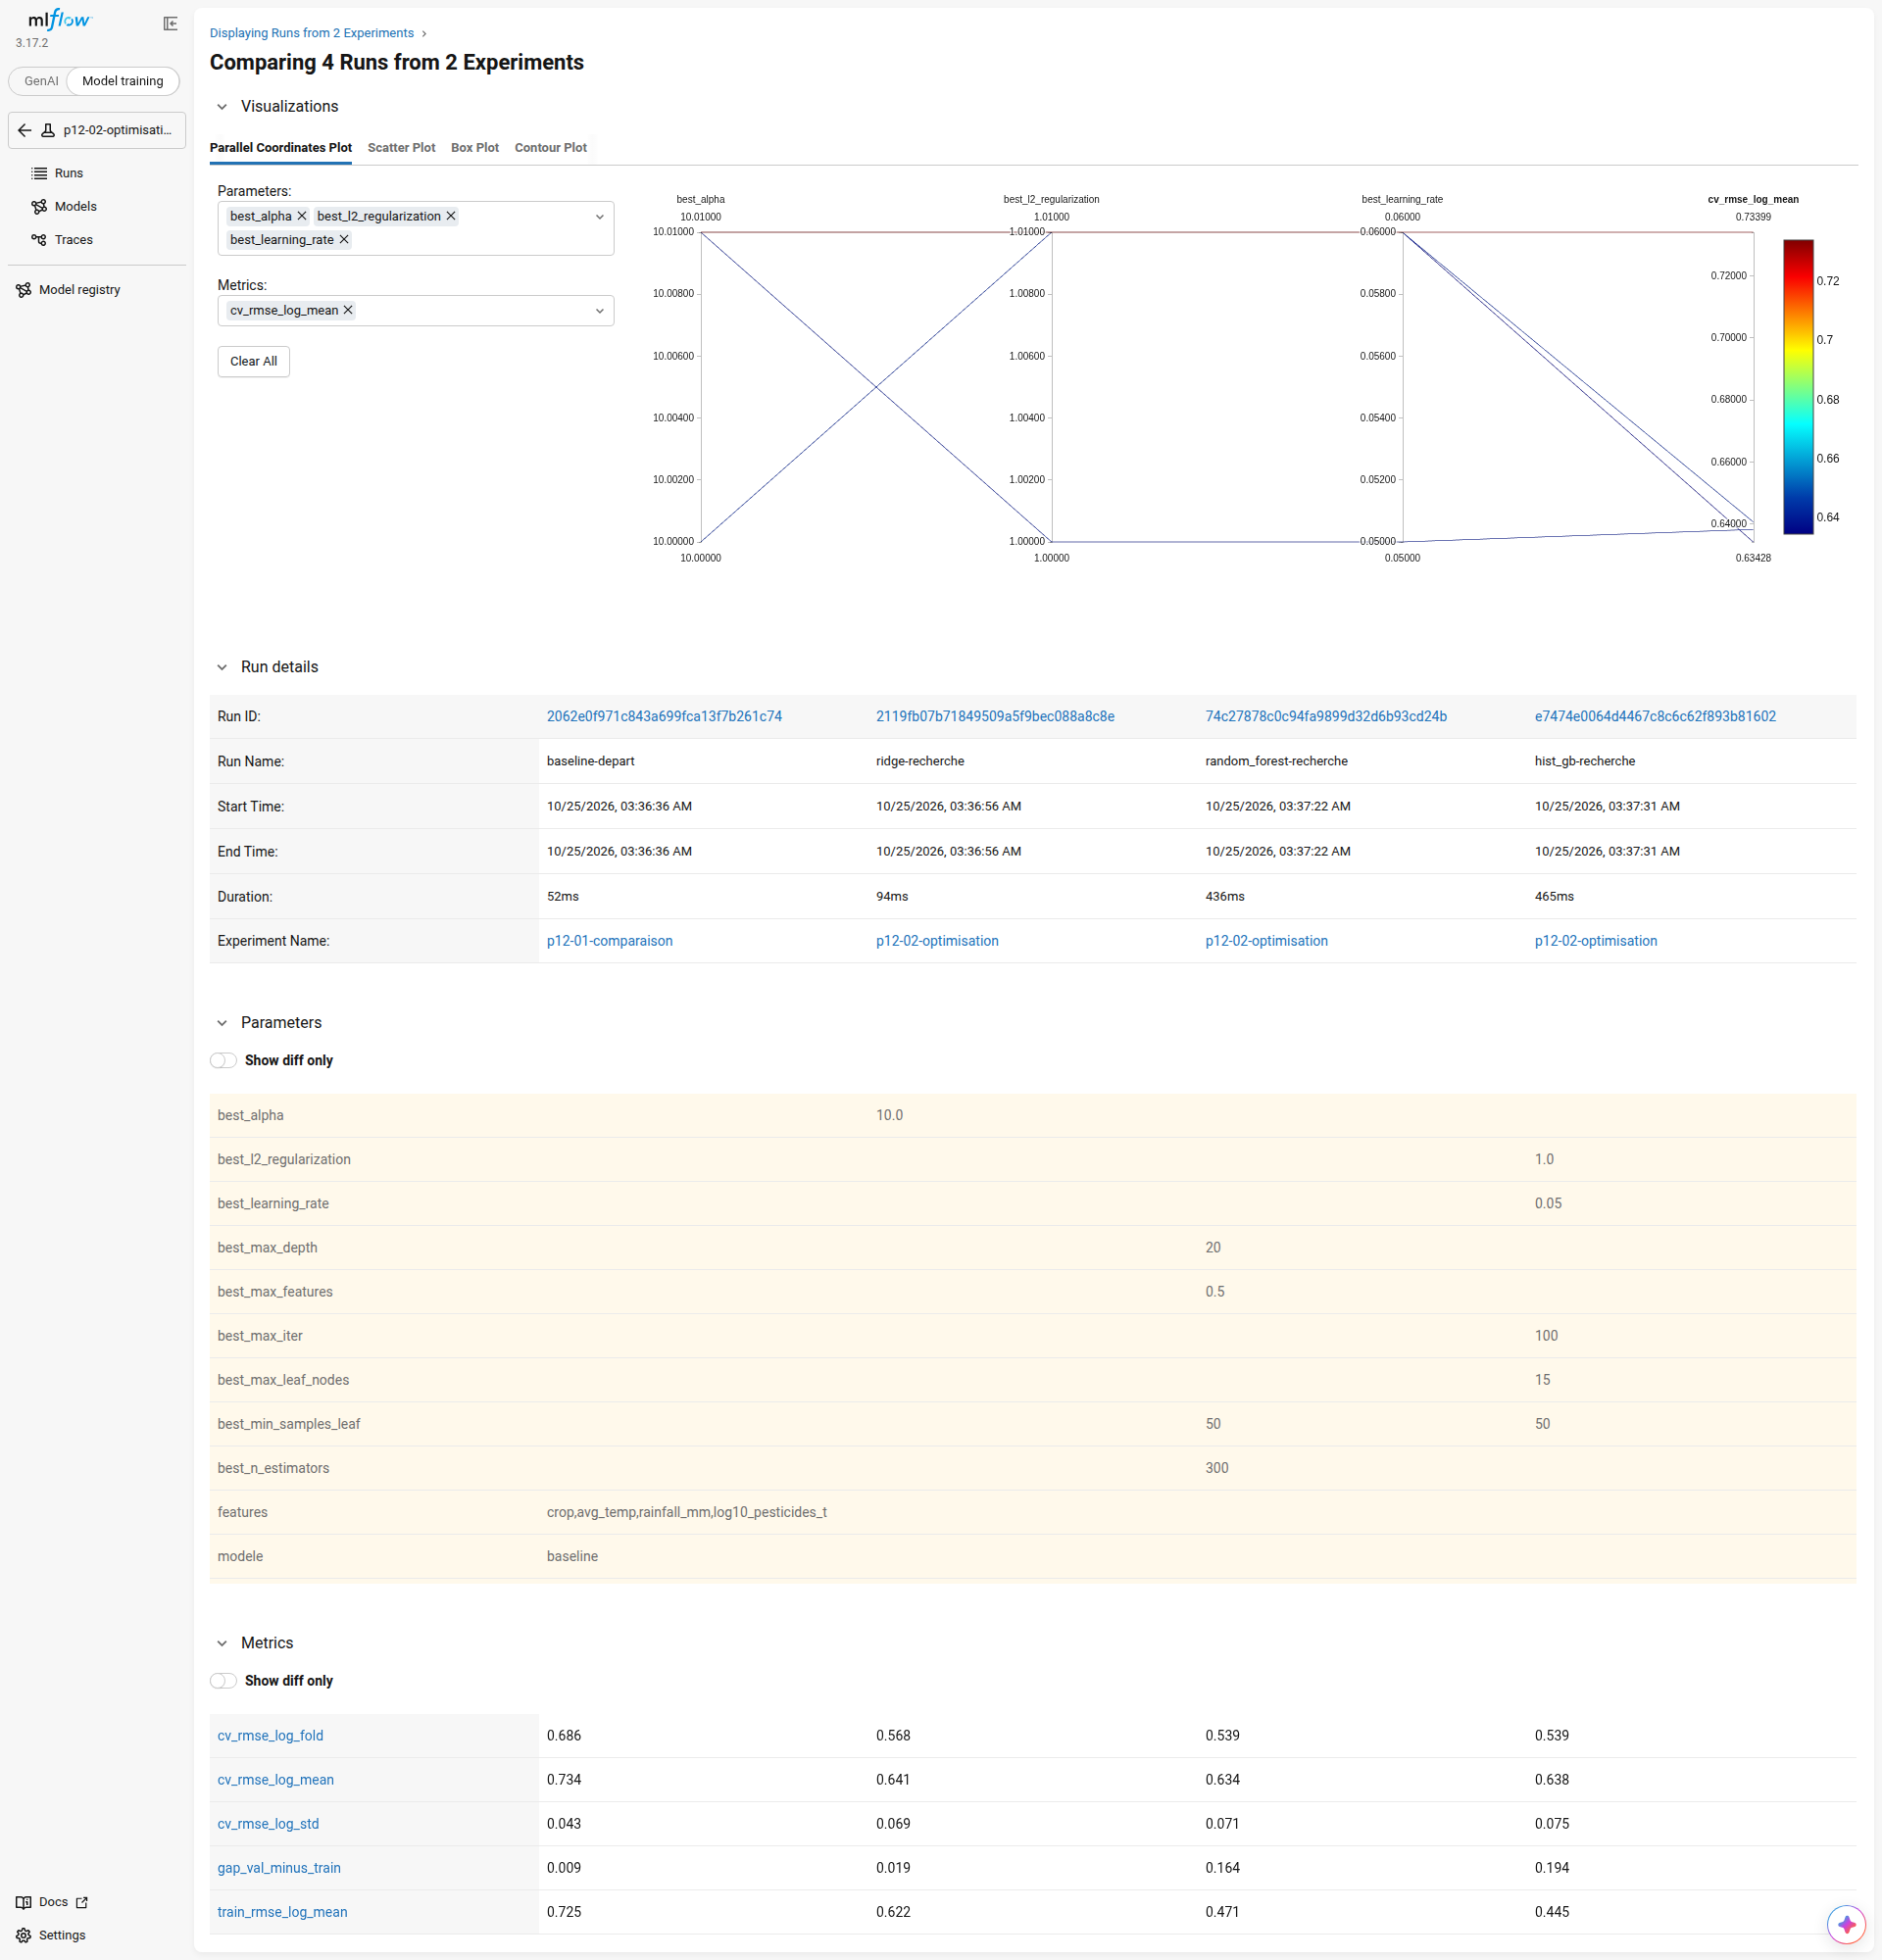

In [19]:
for name in ["mlflow_1_comparaison", "mlflow_2_optimisation", "mlflow_3_comparaison_modeles"]:
    print(name)
    display(Image(filename=str(viz.FIGURES_DIR / f"{name}.png"), width=900))

## 8. Ce qu'on peut dire à un agriculteur (et ce qu'on ne peut pas dire)

**On peut dire :**
- « L'outil estime le rendement **moyen national** d'une culture dans un pays aux conditions données, avec une erreur
  typique d'environ 37 % (erreur relative médiane). Il ne prédit pas le rendement d'une parcelle. »
- « Le classement des cultures ne s'adapte pas aux conditions : il ne fait pas mieux qu'une liste fixe, la même pour
  tous. Il écarte seulement les cultures que personne ne pratique dans des conditions proches. »
- « Les données ne contiennent ni prix ni coûts : l'outil ne dit pas quelle culture est la plus rentable. »

**On ne peut pas dire :** « le modèle recommande mieux que le hasard, donc il est utile » (le hasard n'est pas la
bonne référence) ; « augmenter les pesticides augmente le rendement » ; « la pluie n'a pas d'effet » ; « culture la
plus rentable » ; « le modèle explique 62 % du rendement d'une culture ».

**Pour aller vers une vraie recommandation**, il faudrait des données à la parcelle (sol, irrigation, intrants par
hectare, météo de l'année) et des prix. Ces pistes sont détaillées dans `ALLER_PLUS_LOIN.md`.